# Focused-beam field coupling
Compare the electric-field components of four optical cases near a particle.
Positions are in nm; plotted field magnitudes are in MV/m.

In [1]:
from pathlib import Path
import sys
import numpy as np
import matplotlib.pyplot as plt

root = next(
    path for path in (Path.cwd(), *Path.cwd().parents)
    if (path / 'cases').is_dir()
)
sys.path[:0] = [str(root), str(root / 'src')]
from cases import plane_wave, lg_00, lg_01, lg_02
from optomechanics_levitation import parameters as p


## Field coupling in the focal xy plane
Both rows show the same xy slice at z=0, viewed along the z axis; the + marks the particle
center. The top row shows C_z from E_x and E_y for rotation about z. The bottom row shows
C_y from E_x and E_z for rotation about y. E_z points out of the plotted plane but is
evaluated at each xy position. These maps indicate dipole-limit coupling,
not the full recoil.


In [4]:
beams = [('Plane wave', plane_wave), ('LG00', lg_00), ('LG01', lg_01), ('LG02', lg_02)]
phase = np.linspace(0, 2 * np.pi, 300)

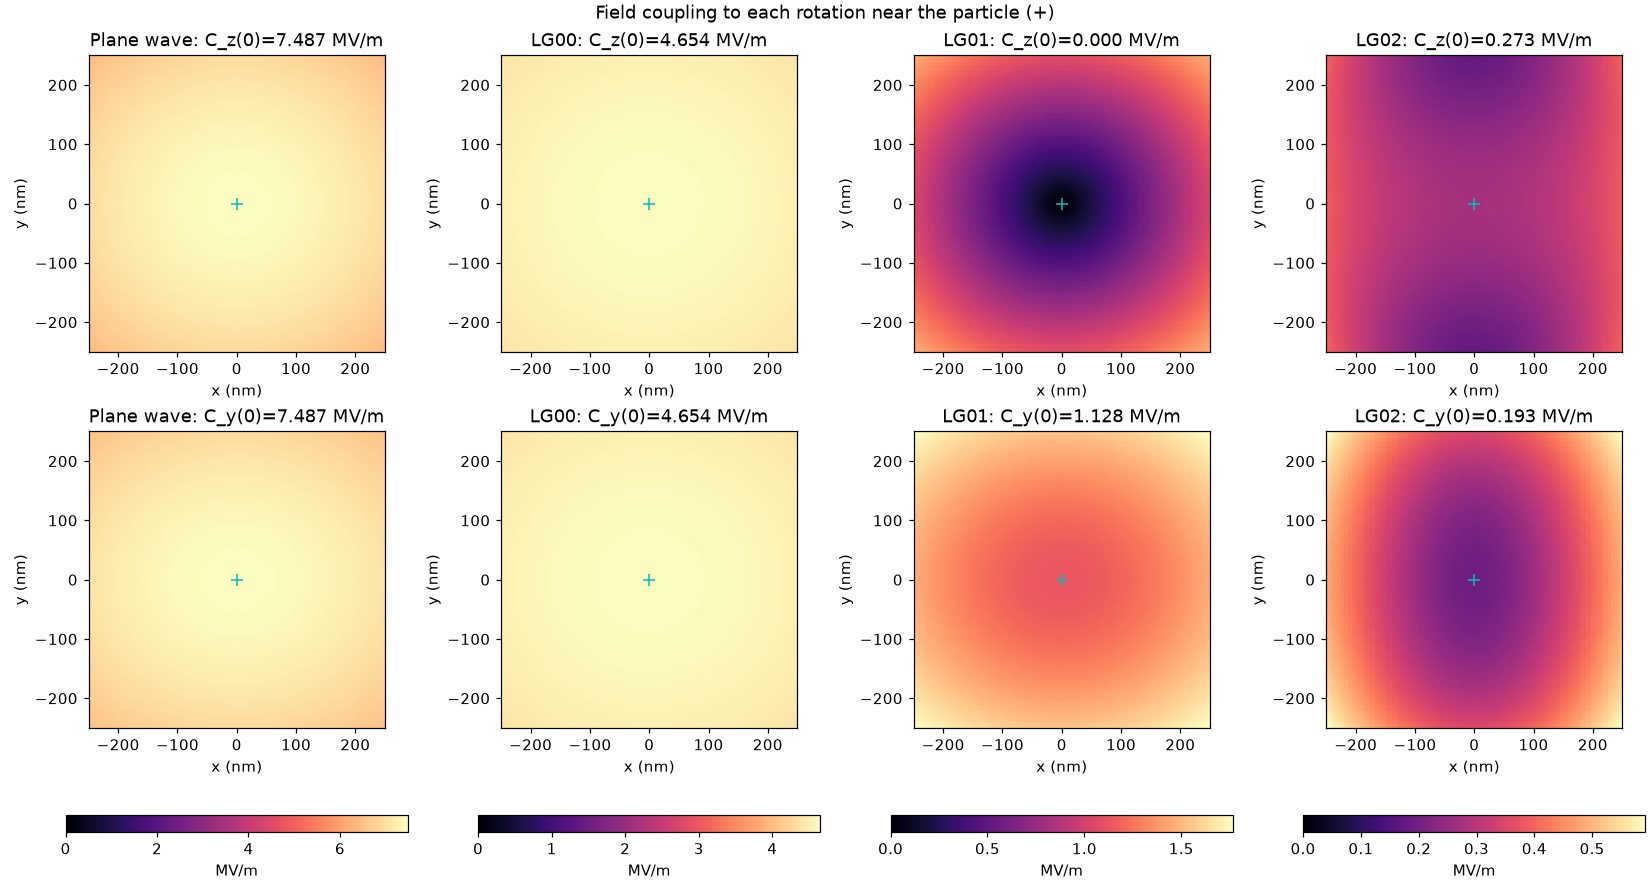

In [5]:
axis_nm = np.linspace(-250, 250, 81)
x, y = np.meshgrid(axis_nm, axis_nm)
points = np.stack((x, y, np.zeros_like(x)), axis=-1)
fig, axes = plt.subplots(2, 4, figsize=(15, 8), constrained_layout=True)

for col, (name, case) in enumerate(beams):
    electric_field = case.electric_field(points)
    coupling_z = np.hypot(np.abs(electric_field[..., 0]), np.abs(electric_field[..., 1]))
    coupling_y = np.hypot(np.abs(electric_field[..., 0]), np.abs(electric_field[..., 2]))
    scale = max(coupling_z.max(), coupling_y.max()) / 1e6

    for row, (values, torque_axis) in enumerate(((coupling_z, 'z'), (coupling_y, 'y'))):
        ax = axes[row, col]
        image = ax.imshow(values / 1e6, origin='lower', extent=(-250, 250, -250, 250),
                          cmap='magma', vmin=0, vmax=scale)
        ax.plot(0, 0, 'c+', ms=8, mew=1)
        ax.set_title(f'{name}: C_{torque_axis}(0)={values[40, 40]/1e6:.3f} MV/m')
        ax.set_xlabel('x (nm)')
        ax.set_ylabel('y (nm)')

    fig.colorbar(image, ax=axes[:, col], orientation='horizontal', label='MV/m')

fig.suptitle('Field coupling to each rotation near the particle (+)')
plt.show()


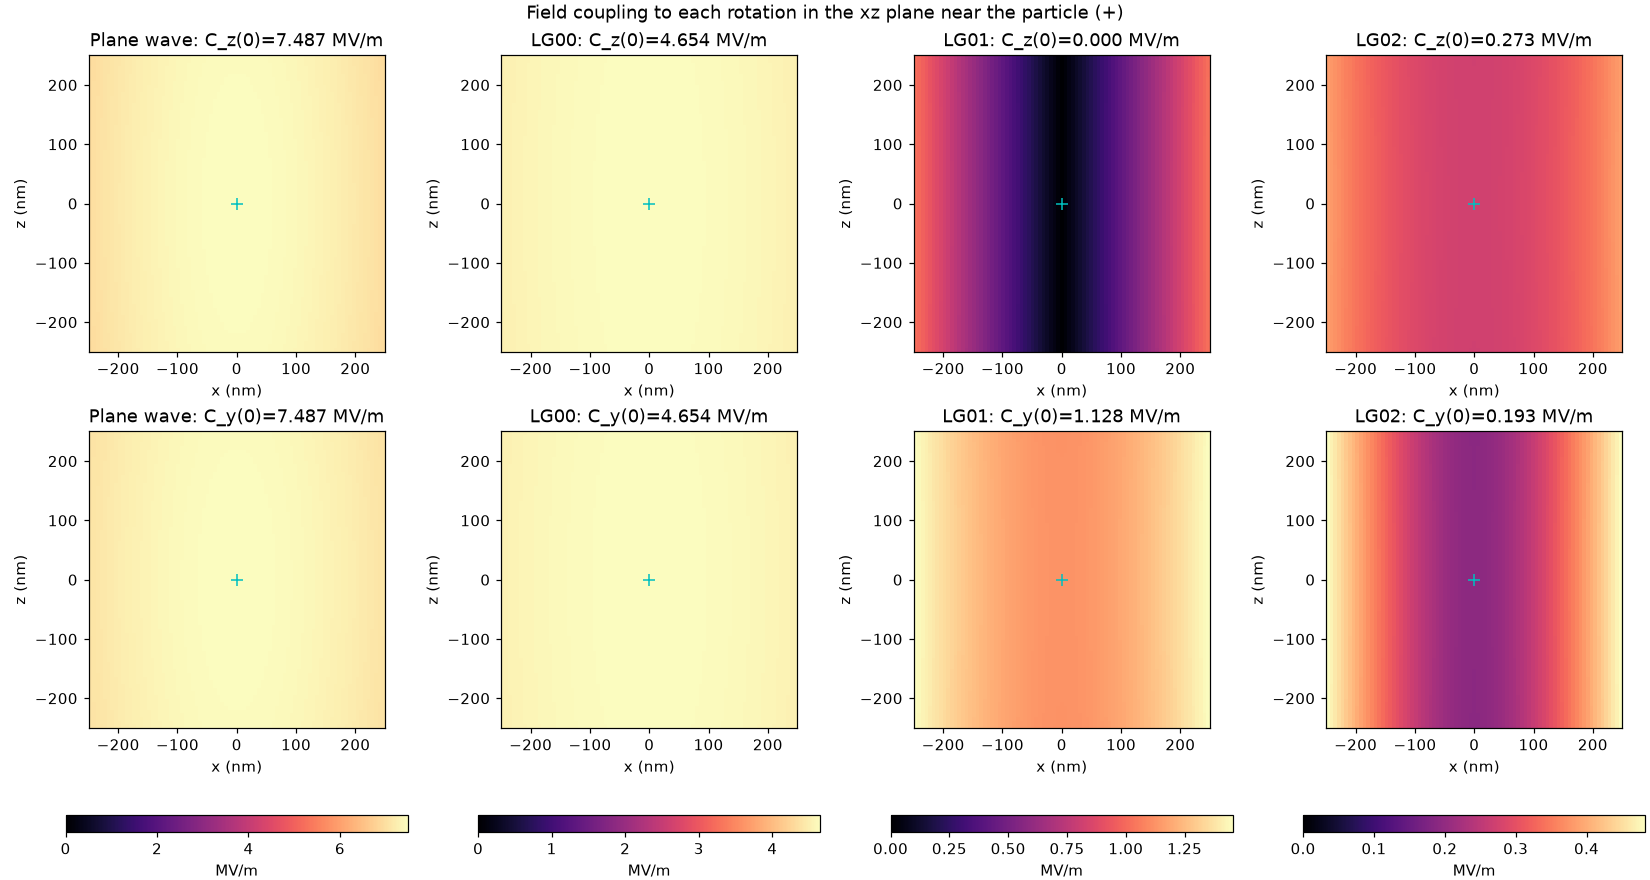

In [6]:
axis_nm = np.linspace(-250, 250, 81)
x, z = np.meshgrid(axis_nm, axis_nm)
points = np.stack((x, np.zeros_like(x), z), axis=-1)
fig, axes = plt.subplots(2, 4, figsize=(15, 8), constrained_layout=True)

for col, (name, case) in enumerate(beams):
    electric_field = case.electric_field(points)
    coupling_z = np.hypot(np.abs(electric_field[..., 0]), np.abs(electric_field[..., 1]))
    coupling_y = np.hypot(np.abs(electric_field[..., 0]), np.abs(electric_field[..., 2]))
    scale = max(coupling_z.max(), coupling_y.max()) / 1e6

    for row, (values, torque_axis) in enumerate(((coupling_z, 'z'), (coupling_y, 'y'))):
        ax = axes[row, col]
        image = ax.imshow(values / 1e6, origin='lower', extent=(-250, 250, -250, 250),
                          cmap='magma', vmin=0, vmax=scale)
        ax.plot(0, 0, 'c+', ms=8, mew=1)
        ax.set_title(f'{name}: C_{torque_axis}(0)={values[40, 40]/1e6:.3f} MV/m')
        ax.set_xlabel('x (nm)')
        ax.set_ylabel('z (nm)')

    fig.colorbar(image, ax=axes[:, col], orientation='horizontal', label='MV/m')

fig.suptitle('Field coupling to each rotation in the xz plane near the particle (+)')
plt.show()
